## Alternative metrics on cellxgene counts, batch dataset, kl2

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

sys.path.append("../../existing_metric_comparison/")
sys.path.append("../../../")
sys.path.append("../../utils/HLCA")
import data_cleanup

# import metrics_lib as metrics
import os
import mapqc

In [2]:
sc.set_figure_params(figsize=(5, 5))

## Set global variables

In [3]:
study = "Sheppard_2020"
batch_variable = "dataset"
kl = "2.0"
use_old_counts = False
if use_old_counts == True:
    suffix = "original_counts_"
else:
    suffix = "cellxgene_counts_"

path_emb = f"/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HLCA/HLCA_and_{study}_{suffix}batch_{batch_variable}_kl{kl}_latent.h5ad"
path_counts = f"/lustre/groups/ml01/workspace/lisa.sikkema/mapqc/data/HLCA/HLCA_and_{study}_counts.h5ad"
path_results_dir = f"/lustre/groups/ml01/code/lisa.sikkema/mapqc/results/HLCA/{study}/{suffix}batch_{batch_variable}_kl{kl}/benchmark"
path_mapqc_results_dir = f"/lustre/groups/ml01/code/lisa.sikkema/mapqc/results/HLCA/{study}/{suffix}batch_{batch_variable}_kl{kl}/mapqc"

In [4]:
if not os.path.exists(path_results_dir):
    if os.path.exists(os.path.dirname(path_results_dir)):
        print(f"Creating directory {path_results_dir}")
        os.mkdir(path_results_dir)
    else:
        print("Parent directory of RESULT_DIR does not exist. Create it first.")

## load and prep Data

In [5]:
adata_emb = sc.read_h5ad(path_emb)
adata_counts = sc.read_h5ad(path_counts)
adata_full = data_cleanup.add_mapping_info_to_counts_adata(adata_counts, adata_emb)

import mapqc results if wanted (for comparison):

In [6]:
results_healthy = mapqc.load(
    os.path.join(path_mapqc_results_dir, "control_edistance_k500.pkl")
)
results_disease = mapqc.load(
    os.path.join(path_mapqc_results_dir, "case_edistance_k500.pkl")
)

## run metrics

### Query healthy

subset to condition of interest? 

In [7]:
query_condition_1 = "Healthy"

In [8]:
adata_1 = adata_full[
    (adata_full.obs.lung_condition == query_condition_1)
    | (adata_full.obs["r_or_q"] == "r")
].copy()

In [9]:
# del adata_full

subset query for metric functions below

In [10]:
adata_query_1 = adata_1[adata_1.obs.study == "Sheppard_2020", :].copy()

set some variables for running metrics

In [11]:
obsm_emb_key = "X_scanvi_emb"
donor_key = "donor_id"
dataset_key = "r_or_q"
sample_key = "sample"
original_emb_key = None
batch_key = "r_or_q"

get results for other metrics:

In [12]:
scib_results_1 = metrics.calculate_scib_metrics(
    adata_1, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False
)

Time to complete scib neighbors calculation: 511.098 s


No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)
../../existing_metric_comparison/metrics_lib.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)
../../existing_metric_comparison/metrics_lib.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)


Time to complete lisi_batch: 27.374 s
Time to complete kbet_batch: 2.451 s


../../existing_metric_comparison/metrics_lib.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)
../../existing_metric_comparison/metrics_lib.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)


In [13]:
symphony_results_1 = metrics.calculate_symphony_metrics(
    adata_1,
    adata_query_1,
    obsm_emb_key,
    donor_key,
    dataset_key,
    sample_key,
    dry_run=False,
)

Time to complete symphony metrics neighbors calculation: 4.143 s


../../existing_metric_comparison/metrics_lib.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)
../../existing_metric_comparison/metrics_lib.py:54: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)


Time to complete lisi_query_donor: 0.759 s
Time to complete wiq_knn_corr: 170.589 s


../../existing_metric_comparison/metrics_lib.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)
../../existing_metric_comparison/metrics_lib.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby(obs_key)


In [14]:
other_results_1 = metrics.calculate_other_metrics(
    adata_1, adata_query_1, obsm_emb_key, dataset_key, sample_key, dry_run=False
)

../../existing_metric_comparison/metrics_lib.py:257: RuntimeWarning: divide by zero encountered in log
  px * np.log(px), axis=1
../../existing_metric_comparison/metrics_lib.py:257: RuntimeWarning: invalid value encountered in multiply
  px * np.log(px), axis=1
../../existing_metric_comparison/metrics_lib.py:257: RuntimeWarning: divide by zero encountered in log
  px * np.log(px), axis=1
../../existing_metric_comparison/metrics_lib.py:257: RuntimeWarning: invalid value encountered in multiply
  px * np.log(px), axis=1
../../existing_metric_comparison/metrics_lib.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby([obs_key, sep_key])


Time to complete cluster_preservation_score: 107.283 s


../../existing_metric_comparison/metrics_lib.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby([obs_key, sep_key])
../../existing_metric_comparison/metrics_lib.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby([obs_key, sep_key])
../../existing_metric_comparison/metrics_lib.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby([obs_key, sep_key])


In [15]:
# save results
adata_1.obs["lisi_batch"] = scib_results_1["lisi_batch"]["per_cell"]
adata_1.obs["kbet_batch"] = scib_results_1["kbet_batch"]["per_cell"]
adata_1.obs["lisi_query_donor"] = symphony_results_1["lisi_query_donor"]["per_cell"]
adata_1.obs["wiq_knn_corr"] = symphony_results_1["wiq_knn_corr"]["per_cell"]
adata_1.obs["cluster_preservation_score"] = other_results_1[
    "cluster_preservation_score"
]["per_cell"]

In [16]:
adata_1.obs[
    [
        "lisi_batch",
        "kbet_batch",
        "lisi_query_donor",
        "wiq_knn_corr",
        "cluster_preservation_score",
    ]
].to_csv(os.path.join(path_results_dir, f"alt_metrics_{query_condition_1.lower()}.csv"))

## Visualize 

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


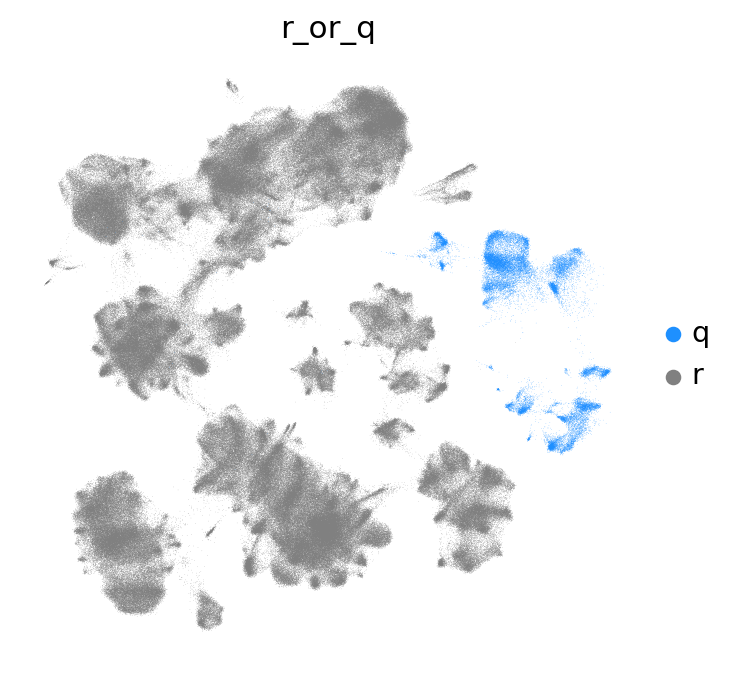

In [17]:
sc.pl.umap(
    adata_1, color="r_or_q", frameon=False, palette={"r": "grey", "q": "dodgerblue"}
)

Run Load and prep embeddings and set global variables first

In [12]:
adata_1.obs[
    [
        "lisi_batch",
        "kbet_batch",
        "lisi_query_donor",
        "wiq_knn_corr",
        "cluster_preservation_score",
    ]
] = pd.read_csv(
    os.path.join(path_results_dir, f"alt_metrics_{query_condition_1.lower()}.csv"),
    index_col="Unnamed: 0",
).loc[
    adata_1.obs.index, :
]

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


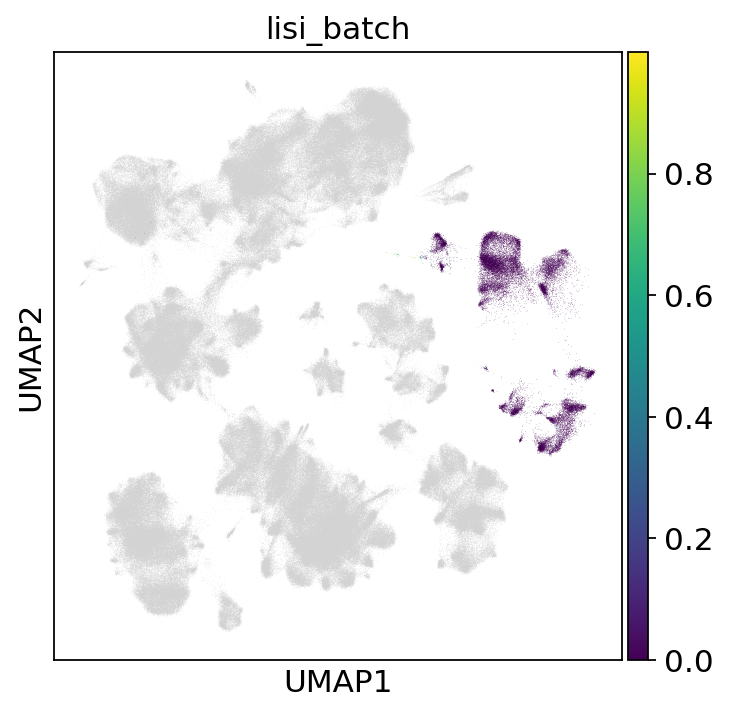

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


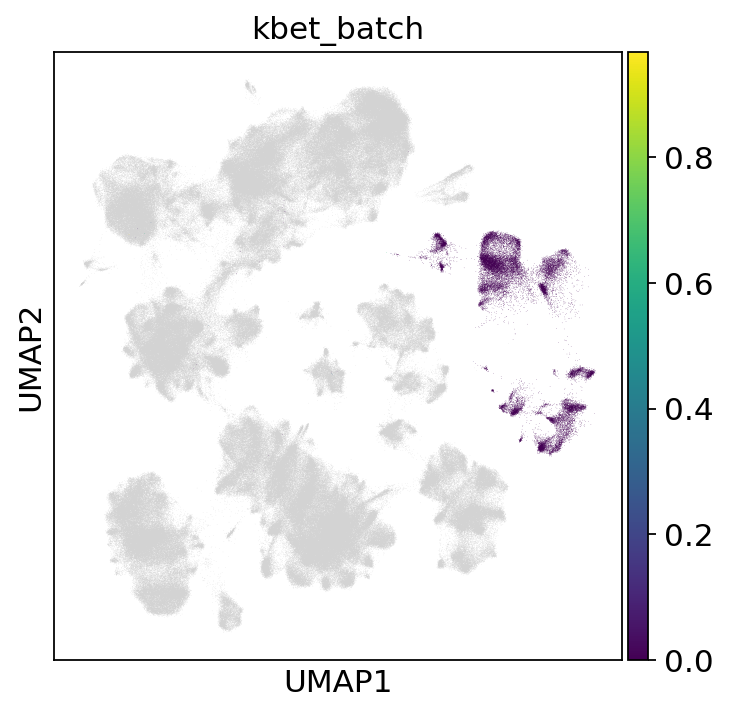

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


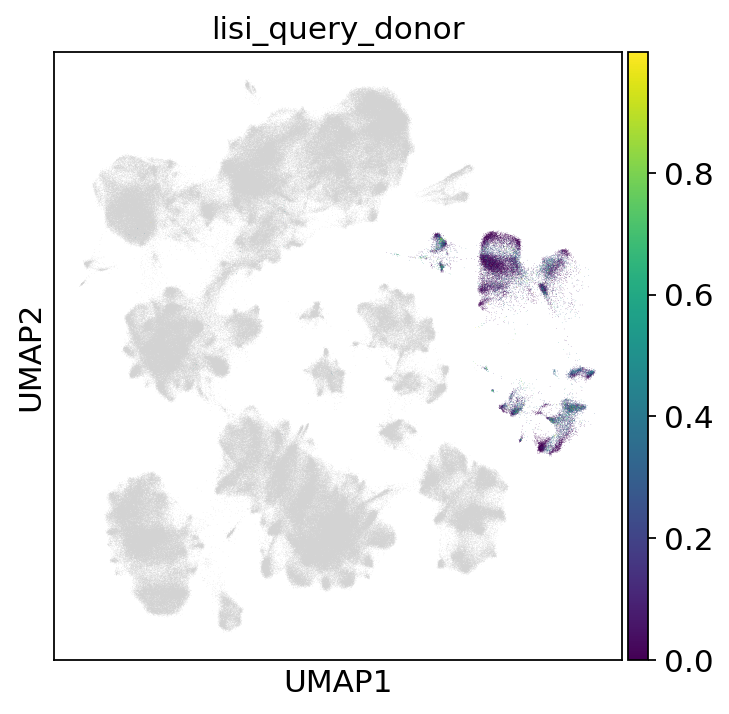

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


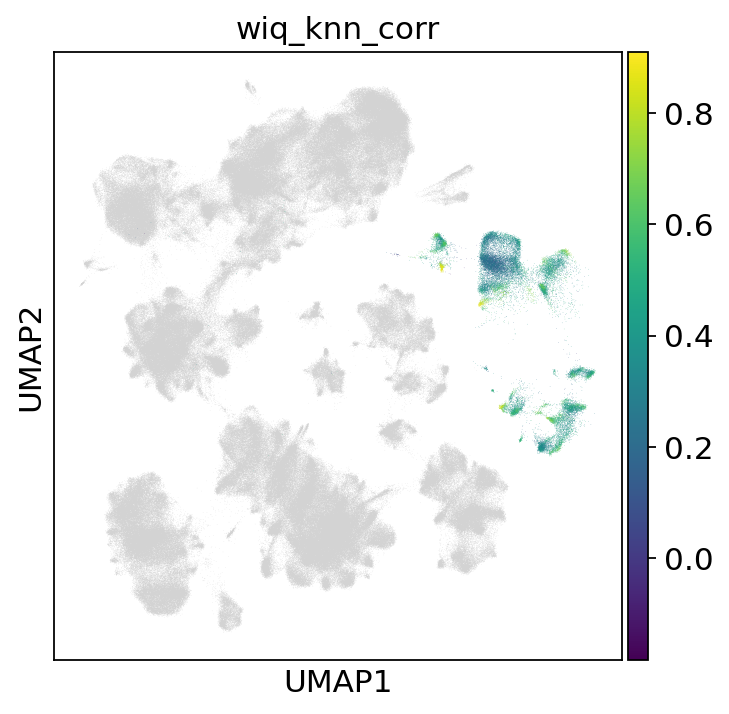

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


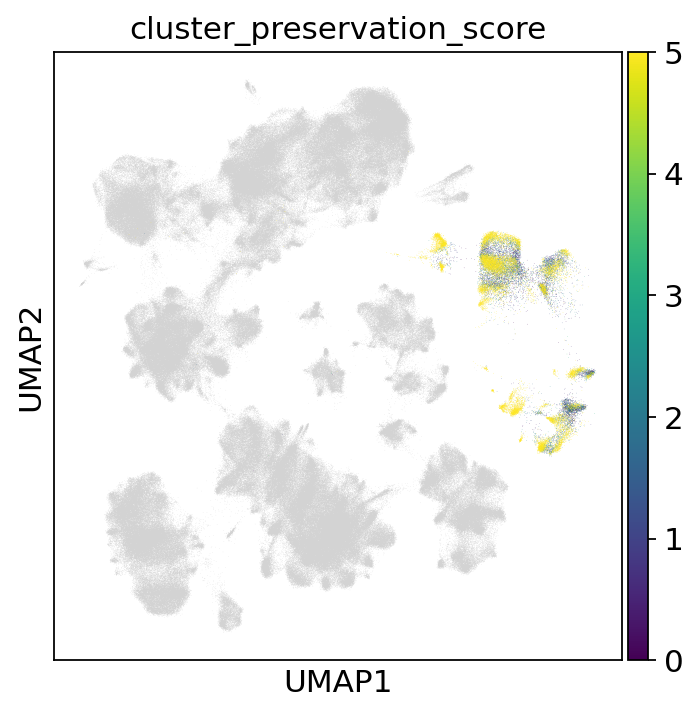

In [19]:
for metric in [
    "lisi_batch",
    "kbet_batch",
    "lisi_query_donor",
    "wiq_knn_corr",
    "cluster_preservation_score",
]:
    adata_1.obs.loc[adata_1.obs.core_or_extension == "core", metric] = np.nan
    sc.pl.umap(adata_1, color=metric)  # ,vmax='p99')

Quantification/visualization different metrics:

In [14]:
hist_kwargs = {
    "wiq_knn_corr": {"range": (-1, 1), "bins": 10},
    "cluster_preservation_score": {"bins": 10},
    "lisi_query_donor": {"bins": 10},
    "lisi_batch": {"bins": 10},
    "kbet_batch": {"range": (0, 1)},
}
xlabels = {
    "wiq_knn_corr": "Within-query\nk-NN-correlation (↑)",
    "cluster_preservation_score": "Cluster preservation\nscore (↑)",
    "lisi_query_donor": "Query donor LISI (↑)",
    "lisi_batch": "Batch LISI (↑)",
    "kbet_batch": "kBET (↑)",
}
results = {}

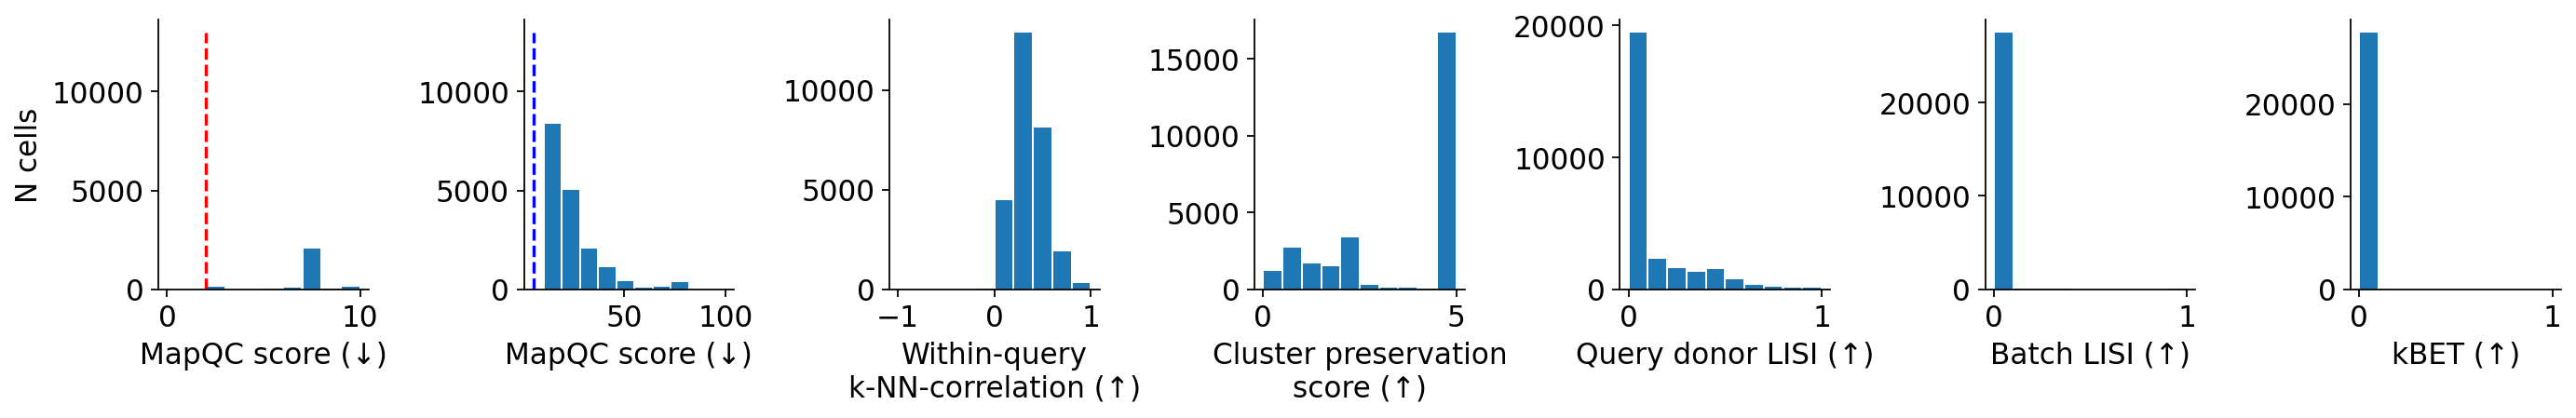

mapqc: {'mean': 21.615134647906384, 'median': 17.732029588671868}
wiq_knn_corr: {'mean': 0.36125698011235147, 'median': 0.34715692462769854}
cluster_preservation_score: {'mean': 3.612313915118936, 'median': 5.0}
lisi_query_donor: {'mean': 0.11349728408543155, 'median': 0.01535573601722715}
lisi_batch: {'mean': 0.0049225842859200505, 'median': 0.0}
kbet_batch: {'mean': 0.00019528859293006933, 'median': 0.0}


In [17]:
alt_metrics_to_include = [
    "wiq_knn_corr",
    "cluster_preservation_score",
    "lisi_query_donor",
    "lisi_batch",
    "kbet_batch",
]
fignumber = 0
n_figures = len(alt_metrics_to_include) + 2
n_cols = n_figures
n_rows = int(np.ceil(n_figures / n_cols))
fig = plt.figure(figsize=(2.5 * n_cols, 3 * n_rows))
fig_count = 1

# start with mapqc scores, x (score) range 0-10
ax = fig.add_subplot(n_rows, n_cols, fig_count)
mapqc_scores = results_healthy.adata.obs.mapqc_score[
    ~pd.isnull(results_healthy.adata.obs.mapqc_score)
]
xmax = 10
# check that we are not ignoring data
ax.hist(
    mapqc_scores,
    bins=10,
    range=(0, xmax),
    rwidth=0.9,
)  # density=True,
ax.set_xlabel("MapQC score (↓)")
ax.set_ylabel("N cells")  # Fraction of cells")
ax.spines[["top", "right"]].set_visible(False)
ax.vlines(x=2, ymin=0, ymax=13000, color="red", linestyle="--")
plt.grid(False)
fig_count += 1

# now plot rest of mapqc range: 10-100
ax = fig.add_subplot(n_rows, n_cols, fig_count)
mapqc_scores = results_healthy.adata.obs.mapqc_score[
    ~pd.isnull(results_healthy.adata.obs.mapqc_score)
]
xmin = 10
xmax = 100
# check that we are not ignoring data
if np.percentile(mapqc_scores, 99) > xmax:
    raise ValueError("You are ignoring more than 1% of your data. Change your xmax.")
ax.hist(mapqc_scores, bins=10, range=(xmin, xmax), rwidth=0.9)  # density=True,
ax.set_xlabel("MapQC score (↓)")
ax.spines[["top", "right"]].set_visible(False)
# plot line for cutting of figure (halfway to 10, where the cut should take place)
ax.vlines(x=5, ymin=0, ymax=13000, color="blue", linestyle="--")
plt.grid(False)
results["mapqc"] = {"mean": np.mean(mapqc_scores), "median": np.median(mapqc_scores)}
fig_count += 1

# then loop through other metrics
for metric in alt_metrics_to_include:
    ax = fig.add_subplot(n_rows, n_cols, fig_count)
    metric_vals = adata_1.obs[metric][adata_1.obs.r_or_q == "q"]
    ax.hist(metric_vals, rwidth=0.9, **hist_kwargs[metric])
    ax.set_ylabel("N cells")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel(xlabels[metric])
    ax.yaxis.label.set_visible(
        False
    )  # remove y-axis label, it's the same for all plots
    fig_count += 1
    plt.grid(False)
    results[metric] = {"mean": np.mean(metric_vals), "median": np.median(metric_vals)}
plt.tight_layout()
plt.show()
plt.close()
for metric, res in results.items():
    print(f"{metric}: {res}")

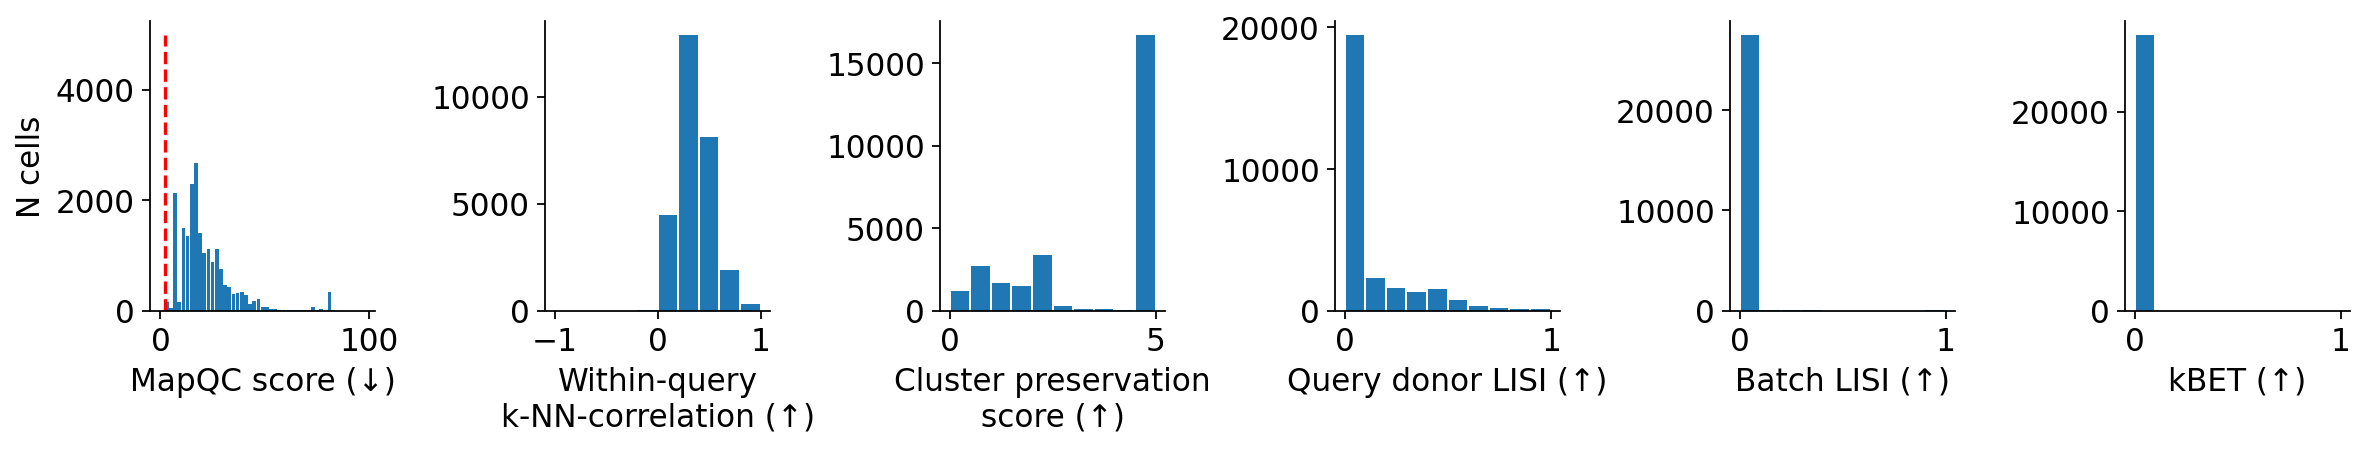

mapqc: {'mean': 21.615134647906384, 'median': 17.732029588671868}
wiq_knn_corr: {'mean': 0.36125698011235147, 'median': 0.34715692462769854}
cluster_preservation_score: {'mean': 3.612313915118936, 'median': 5.0}
lisi_query_donor: {'mean': 0.11349728408543155, 'median': 0.01535573601722715}
lisi_batch: {'mean': 0.0049225842859200505, 'median': 0.0}
kbet_batch: {'mean': 0.00019528859293006933, 'median': 0.0}


In [17]:
alt_metrics_to_include = [
    "wiq_knn_corr",
    "cluster_preservation_score",
    "lisi_query_donor",
    "lisi_batch",
    "kbet_batch",
]
fignumber = 0
n_figures = len(alt_metrics_to_include) + 1
n_cols = n_figures
n_rows = int(np.ceil(n_figures / n_cols))
fig = plt.figure(figsize=(2.5 * n_cols, 3 * n_rows))
fig_count = 1

# start with mapqc scores
ax = fig.add_subplot(n_rows, n_cols, fig_count)
mapqc_scores = results_healthy.adata.obs.mapqc_score[
    ~pd.isnull(results_healthy.adata.obs.mapqc_score)
]
xmax = 100
# check that we are not ignoring data
if np.percentile(mapqc_scores, 99) > xmax:
    raise ValueError("You are ignoring more than 1% of your data. Change your xmax.")
ax.hist(
    mapqc_scores, bins=range(0, xmax, 2), range=(0, xmax), rwidth=0.9
)  # density=True,
ax.set_xlabel("MapQC score (↓)")
ax.set_ylabel("N cells")  # Fraction of cells")
ax.spines[["top", "right"]].set_visible(False)
ax.vlines(x=2, ymin=0, ymax=5000, color="red", linestyle="--")
plt.grid(False)
results["mapqc"] = {"mean": np.mean(mapqc_scores), "median": np.median(mapqc_scores)}
fig_count += 1

# then loop through other metrics
for metric in alt_metrics_to_include:
    ax = fig.add_subplot(n_rows, n_cols, fig_count)
    metric_vals = adata_1.obs[metric][adata_1.obs.r_or_q == "q"]
    ax.hist(metric_vals, rwidth=0.9, **hist_kwargs[metric])
    ax.set_ylabel("N cells")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel(xlabels[metric])
    ax.yaxis.label.set_visible(False)
    fig_count += 1
    plt.grid(False)
    results[metric] = {"mean": np.mean(metric_vals), "median": np.median(metric_vals)}
plt.tight_layout()
plt.show()
plt.close()
for metric, res in results.items():
    print(f"{metric}: {res}")

### Query disease (not used for the paper figure)

In [17]:
query_condition_2 = "IPF"

In [18]:
adata_2 = adata_full[
    (adata_full.obs.lung_condition == query_condition_2)
    | (adata_full.obs["r_or_q"] == "r")
].copy()

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/anndata/_core/anndata.py:1113: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(df_full[k]):


In [19]:
del adata_full

subset query for metric functions below

In [20]:
adata_query_2 = adata_2[adata_2.obs.study == "Sheppard_2020", :].copy()

set some variables for running metrics

In [21]:
obsm_emb_key = "X_scanvi_emb"
donor_key = "donor_id"
dataset_key = "r_or_q"
sample_key = "sample"
original_emb_key = None
batch_key = "r_or_q"

get results for other metrics:

In [22]:
scib_results_2 = metrics.calculate_scib_metrics(
    adata_2, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False
)

Time to complete scib neighbors calculation: 501.020 s


../../existing_metric_comparison/metrics_lib.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).median(['score'])['score'].apply(after_function)
../../existing_metric_comparison/metrics_lib.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).median(['score'])['score'].apply(after_function)


Time to complete lisi_batch: 11.113 s
Time to complete kbet_batch: 1.911 s


../../existing_metric_comparison/metrics_lib.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).mean(['score'])['score'].apply(after_function)
../../existing_metric_comparison/metrics_lib.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).mean(['score'])['score'].apply(after_function)


In [23]:
symphony_results_2 = metrics.calculate_symphony_metrics(
    adata_2,
    adata_query_2,
    obsm_emb_key,
    donor_key,
    dataset_key,
    sample_key,
    dry_run=False,
)

Time to complete symphony metrics neighbors calculation: 5.167 s


../../existing_metric_comparison/metrics_lib.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).median(['score'])['score'].apply(after_function)
../../existing_metric_comparison/metrics_lib.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).median(['score'])['score'].apply(after_function)


Time to complete lisi_query_donor: 0.795 s
Time to complete wiq_knn_corr: 175.055 s


../../existing_metric_comparison/metrics_lib.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).mean(['score'])['score'].apply(after_function)
../../existing_metric_comparison/metrics_lib.py:38: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  results[title] = res_pd.groupby(obs_key).mean(['score'])['score'].apply(after_function)


In [24]:
other_results_2 = metrics.calculate_other_metrics(
    adata_2, adata_query_2, obsm_emb_key, dataset_key, sample_key, dry_run=False
)

../../existing_metric_comparison/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
../../existing_metric_comparison/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
../../existing_metric_comparison/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
../../existing_metric_comparison/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 115.093 s


../../existing_metric_comparison/metrics_lib.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby([obs_key, sep_key]).mean(['score']).reset_index()
../../existing_metric_comparison/metrics_lib.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res_pd.groupby([obs_key, sep_key]).mean(['score']).reset_index()
../../existing_metric_comparison/metrics_lib.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  

In [25]:
# save results
adata_2.obs["lisi_batch"] = scib_results_2["lisi_batch"]["per_cell"]
adata_2.obs["kbet_batch"] = scib_results_2["kbet_batch"]["per_cell"]
adata_2.obs["lisi_query_donor"] = symphony_results_2["lisi_query_donor"]["per_cell"]
adata_2.obs["wiq_knn_corr"] = symphony_results_2["wiq_knn_corr"]["per_cell"]
adata_2.obs["cluster_preservation_score"] = other_results_2[
    "cluster_preservation_score"
]["per_cell"]

In [26]:
adata_2.obs[
    [
        "lisi_batch",
        "kbet_batch",
        "lisi_query_donor",
        "wiq_knn_corr",
        "cluster_preservation_score",
    ]
].to_csv(os.path.join(path_results_dir, f"alt_metrics_{query_condition_2.lower()}.csv"))

## Visualize 

Run Load and prep embeddings and set global variables first

In [27]:
adata_2.obs[
    [
        "lisi_batch",
        "kbet_batch",
        "lisi_query_donor",
        "wiq_knn_corr",
        "cluster_preservation_score",
    ]
] = pd.read_csv(
    os.path.join(path_results_dir, f"alt_metrics_{query_condition_2.lower()}.csv"),
    index_col="Unnamed: 0",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


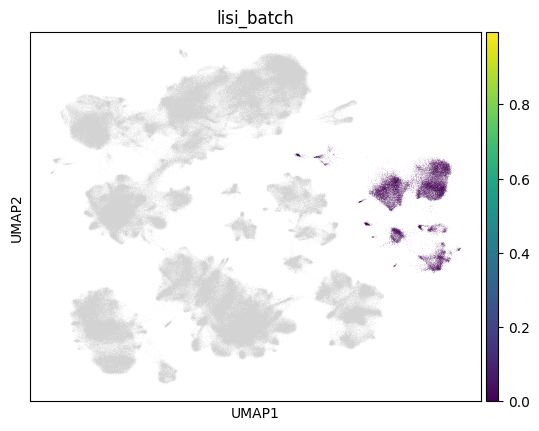

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


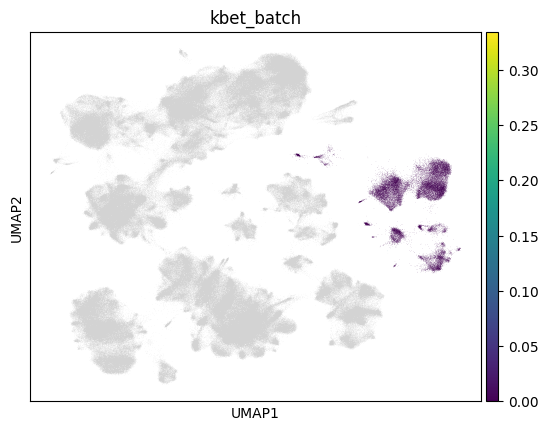

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


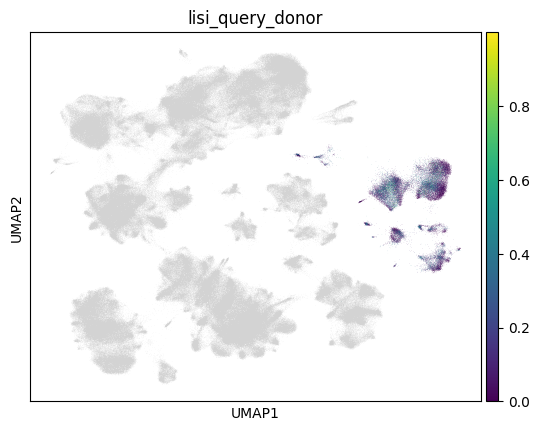

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


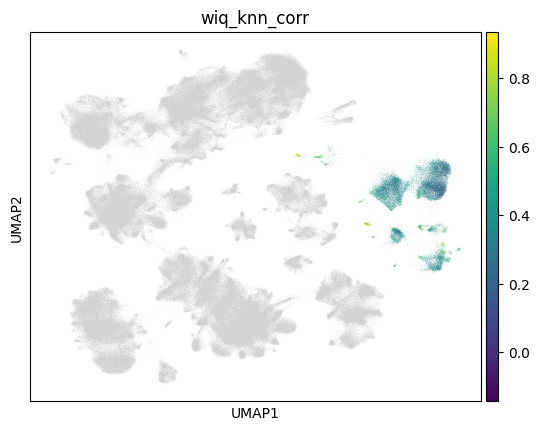

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_benchmark/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1208: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):


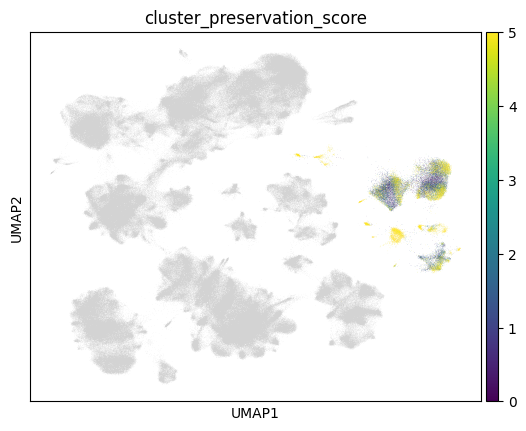

In [28]:
for metric in [
    "lisi_batch",
    "kbet_batch",
    "lisi_query_donor",
    "wiq_knn_corr",
    "cluster_preservation_score",
]:
    adata_2.obs.loc[adata_2.obs.core_or_extension == "core", metric] = np.nan
    sc.pl.umap(adata_2, color=metric)  # ,vmax='p99')